# Day 01 — K-Means Experiments

Three experiments on K-Means:

1. **Unsupervised K-Means** — compare K=3 and K=4 on 400 synthetic 2-D points.
2. **Elbow Method** — plot inertia for K=1 to K=10.
3. **Semi-supervised K-Means** — use known labels to constrain assignments in a 1-D toy example.

The 2-D data are stored in `X_blobs` and the 1-D demo data in `X_toy`, so the notebook can run from top to bottom without overwriting variables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

## 1. Unsupervised K-Means

Generate 400 points from four true clusters, then fit K-Means with K=3 and K=4.

In [2]:
# 400 points, 4 true centers
X_blobs, y_true_blobs = make_blobs(
    n_samples=400,
    centers=4,
    cluster_std=1.2,
    random_state=42,
)

print(f"X_blobs shape: {X_blobs.shape}")
print(f"True cluster sizes: {np.bincount(y_true_blobs)}")

X_blobs shape: (400, 2)
True cluster sizes: [100 100 100 100]


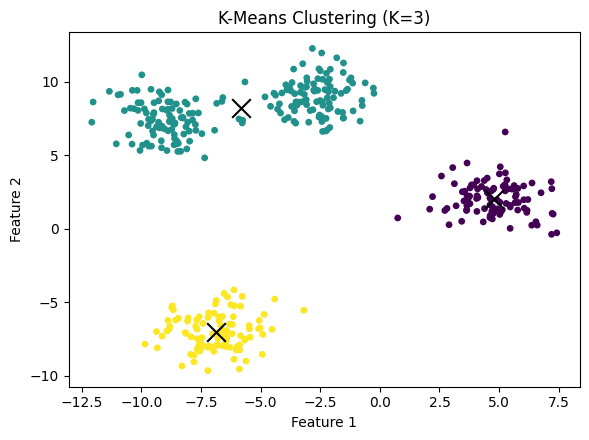

K=3 inertia: 3218.6614


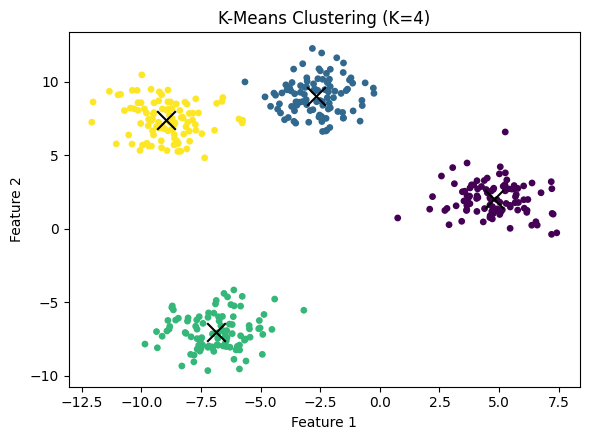

K=4 inertia: 1103.7864


In [3]:
inertias = {}

for k in (3, 4):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_blobs)
    inertias[k] = model.inertia_

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, s=15)
    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker="x",
        s=180,
        c="black",
    )
    ax.set_title(f"K-Means Clustering (K={k})")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    fig.tight_layout()
    fig.savefig(f"figures/kmeans_k{k}.png", dpi=150)
    plt.show()

    print(f"K={k} inertia: {model.inertia_:.4f}")

### Result

K=3 has a larger inertia than K=4 because one extra centroid can reduce the distance between points and their assigned centers. The data were generated from four clusters, so K=3 is forced to merge two of them.

## 2. Elbow Method

Fit K=1 to K=10 on the same `X_blobs` data and plot inertia.

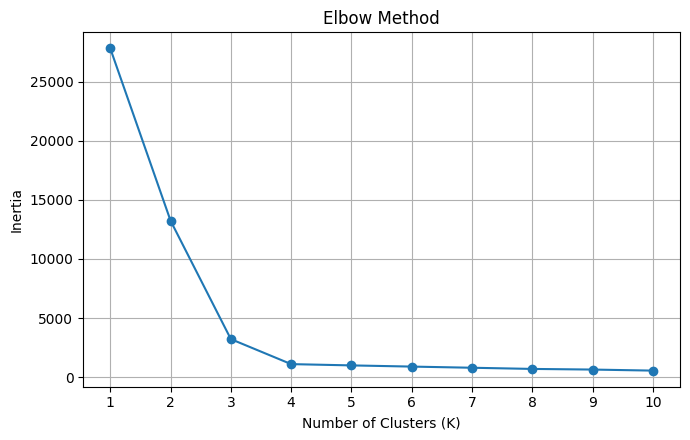

K= 1 inertia=27811.1843
K= 2 inertia=13234.2929
K= 3 inertia=3218.6614
K= 4 inertia=1103.7864
K= 5 inertia=995.4031
K= 6 inertia=894.9240
K= 7 inertia=796.8036
K= 8 inertia=697.3256
K= 9 inertia=643.4921
K=10 inertia=554.3528


In [4]:
elbow_inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_blobs)
    elbow_inertias.append(model.inertia_)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, 11), elbow_inertias, marker="o")
ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow Method")
ax.set_xticks(range(1, 11))
ax.grid(True)
fig.tight_layout()
fig.savefig("figures/elbow_method.png", dpi=150)
plt.show()

for k, inertia in zip(range(1, 11), elbow_inertias):
    print(f"K={k:2d} inertia={inertia:.4f}")

### Result

Inertia drops sharply from K=1 to K=4 and then flattens. The elbow is around **K=4**, which matches the four true clusters used to generate the data.

## 3. Semi-supervised K-Means (1-D toy example)

Known labels: `0` = cat, `1` = dog, `-1` = unknown. Labeled points keep their given assignment; only unlabeled points are assigned by nearest center.

In [5]:
X_toy = np.array([1., 8., 10., 3.])
centers_toy = np.array([1., 9.])
labels_toy = np.array([0, 1, 1, -1])  # 0=cat, 1=dog, -1=unknown

# Step 1: ordinary nearest-center assignment
distances_toy = np.abs(X_toy[:, None] - centers_toy[None, :])
ordinary_assignments = np.argmin(distances_toy, axis=1)

# Step 2: force known labels with a boolean mask
known = labels_toy != -1
constrained_assignments = ordinary_assignments.copy()
constrained_assignments[known] = labels_toy[known]

# Step 3: update centers from the constrained assignments
new_centers_toy = np.array([
    X_toy[constrained_assignments == k].mean()
    for k in range(2)
])

print("Distances to centers [1, 9]:")
print(distances_toy)
print()
print(f"{'x':>4} | {'label':>5} | {'status':>9} | {'ordinary':>8} | {'final':>5}")
print("-" * 45)
for x, label, ordinary, final in zip(
    X_toy, labels_toy, ordinary_assignments, constrained_assignments
):
    status = "labeled" if label != -1 else "unlabeled"
    print(f"{x:>4.0f} | {label:>5d} | {status:>9} | {ordinary:>8d} | {final:>5d}")

print()
print("New centers:", new_centers_toy)

Distances to centers [1, 9]:
[[0. 8.]
 [7. 1.]
 [9. 1.]
 [2. 6.]]

   x | label |    status | ordinary | final
---------------------------------------------
   1 |     0 |   labeled |        0 |     0
   8 |     1 |   labeled |        1 |     1
  10 |     1 |   labeled |        1 |     1
   3 |    -1 | unlabeled |        0 |     0

New centers: [2. 9.]


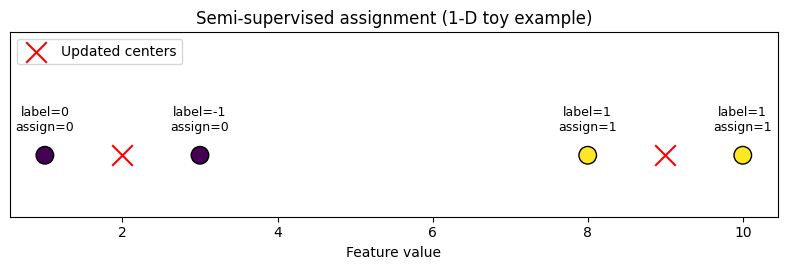

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.scatter(
    X_toy,
    np.zeros_like(X_toy),
    c=constrained_assignments,
    cmap="viridis",
    s=160,
    edgecolors="black",
    zorder=3,
)
ax.scatter(
    new_centers_toy,
    np.zeros(2),
    marker="x",
    s=220,
    c="red",
    label="Updated centers",
    zorder=4,
)
for x, label, assignment in zip(X_toy, labels_toy, constrained_assignments):
    ax.annotate(
        f"label={label}\nassign={assignment}",
        (x, 0.06),
        ha="center",
        fontsize=9,
    )
ax.set_xlabel("Feature value")
ax.set_yticks([])
ax.set_ylim(-0.15, 0.30)
ax.set_title("Semi-supervised assignment (1-D toy example)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/semi_supervised_toy.png", dpi=150)
plt.show()

### Result

The three labeled points (1, 8, 10) keep labels 0, 1, 1. The unlabeled point (3) is assigned to the nearest center, cluster 0. In this example the known labels already agree with the nearest-center assignments, so the final assignment vector equals the ordinary one. The boolean mask still enforces the constraint: if a known label disagreed with the nearest center, the label would override the distance-based result. After the update, the centers move from [1, 9] to [2, 9].

## Summary

- K=3 inertia: 3218.6614; K=4 inertia: 1103.7864.
- The elbow appears at K=4, matching the four true clusters.
- In the semi-supervised toy example, known labels constrain assignments via a boolean mask, while unknown points are assigned by distance.